# Project 2: An HPLC calibration across gradient lengths

**Question.** Does the calibration slope of each analyte depend on the length of the solvent gradient, beyond the uncertainty from replicate injections, and does the scatter about each calibration line come from the injections or from the standards?

**Data.** `data/knoevenagel.tar.bz2`, the Knoevenagel example set of MOCCA, an open-source chromatography package, downloaded on 2026-11-08 from https://github.com/Bayer-Group/MOCCA/blob/example-data/knoevenagel.tar.bz2 and committed exactly as downloaded (52,889,896 bytes). On 2026-11-22 that repository returned "404 Not Found". Haas, C. P. et al., *ACS Cent. Sci.* **9**, 307 (2023), doi:10.1021/acscentsci.2c01042. License MIT.

**Concentrations.** The weighed concentrations of the standards are not in the data files. They are copied into the Parameters section from the package's loader source in mocca2 0.1.18 on PyPI, https://pypi.org/project/mocca2/0.1.18/, file `src/mocca2/example_data/loaders.py`, lines 159 to 163, accessed 2026-11-22.

**What one row is.** Each HPLC run is one `DAD1.CSV` file inside the archive. One row is one time point of the diode-array detector: the time in min, then the absorbance in mAU at each wavelength from 200 to 550 nm in 1 nm steps.

**This draft.** The first analysis is one calibration line: benzaldehyde on the 2.50 min gradient, at one wavelength, from both replicate series.

## Parameters

Every number that encodes a scientific choice is set here, with its unit and reason: the analyte and gradient of the first analysis, the detection wavelength, the integration window, the weighed concentrations, and the standards left out of the fit. Nothing is printed.

In [1]:
import re
import sys
import tarfile

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
from scipy.stats import linregress

# Data file, committed in data/ exactly as downloaded
ARCHIVE_PATH = "data/knoevenagel.tar.bz2"

# The first analysis uses one analyte on one gradient, written as in the run names
ANALYTE = "ba"  # benzaldehyde; the other analytes are "ome" and "nme2"
GRADIENT_CODE = "250"  # gradient length in hundredths of a minute: 2.50 min, the longest of the five

# Detection wavelength, nm: benzaldehyde's absorption maximum above 240 nm, where the blank is low (spectrum figure)
WAVELENGTH_NM = 249

# Half-width of the integration window around the peak apex, min: 0.05 min = 3 s,
# several times the peak's width at half height (about 0.8 s)
HALF_WINDOW_MIN = 0.05

# Weighed concentrations of the standards, mM, by analyte and by the nominal level in the run name.
# Source: mocca2 0.1.18 on PyPI, https://pypi.org/project/mocca2/0.1.18/,
# file src/mocca2/example_data/loaders.py, lines 159 to 163, accessed 2026-11-22
CONCENTRATIONS_MM = {
    "ba": {"100": 0.9947, "075": 0.7618, "050": 0.4841, "025": 0.2486},
    "ome": {"100": 1.3162, "075": 0.9911, "050": 0.6379, "025": 0.2968},
    "nme2": {"100": 0.9676, "075": 0.7219, "050": 0.4753, "025": 0.2483},
}

# Standards left out of the calibration fit, as (series, level); the reason is in the calibration section
EXCLUDED_STANDARDS = [(1, "075")]

## Load the runs

This cell reads the archive once, straight from the `.tar.bz2` file, so the committed file is never extracted or changed. It lists every calibration run and keeps the full data only for the blanks and benzaldehyde standards on the 2.50 min gradient, which keeps memory small. The reaction runs in the archive are not used.

A run name such as `2022-03-24_12-38-34_250_ba_100` gives the date and time of the run, the gradient length in hundredths of a minute (`250` = 2.50 min), the analyte (`ba` benzaldehyde, `ome` 4-methoxybenzaldehyde, `nme2` 4-(dimethylamino)benzaldehyde) and the nominal level of the standard (`100`, `075`, `050`, `025`). Runs ending `_grad` are blanks. The two `first_grad` runs at the start of each series, run before any standard, are taken to be column conditioning and are not used; MOCCA's own loader also skips them.

Expected output: 144 calibration runs, 12 of them loaded, and in each series 4 standards per analyte and 2 blanks for each of the 5 gradient lengths. The cell takes about 20 s.

In [2]:
# Each calibration run is a folder such as calibration1/2022-03-24_12-38-34_250_ba_100.D/DAD1.CSV
run_pattern = re.compile(r"calibration(?P<series>[12])/(?P<run>[\d-]+_[\d-]+_(?P<label>\w+))\.D/DAD1\.CSV$")


def describe_label(label):
    """Split a run label such as 250_ba_100, 250_grad or first_grad into its parts."""
    parts = label.split("_")
    if parts[0] == "first":
        return {"kind": "conditioning", "gradient_code": None, "analyte": None, "level": None}
    if parts[1] == "grad":
        return {"kind": "blank", "gradient_code": parts[0], "analyte": None, "level": None}
    return {"kind": "standard", "gradient_code": parts[0], "analyte": parts[1], "level": parts[2]}


def read_run(file):
    """Read one DAD1.CSV: UTF-16 text, an unnamed time column, then one column per wavelength."""
    run = pd.read_csv(file, encoding="utf-16")
    return run.rename(columns={"Unnamed: 0": "time_min"})  # time, min


catalogue_rows = []
runs = {}  # full data for the blanks and standards of the chosen analyte and gradient, by run name

with tarfile.open(ARCHIVE_PATH, "r:bz2") as archive:
    for member in archive:
        match = run_pattern.search(member.name)
        if match is None:
            continue  # folders, and the reaction runs, which this analysis does not use
        info = {"series": int(match["series"]), "run": match["run"]} | describe_label(match["label"])
        catalogue_rows.append(info)
        on_gradient = info["gradient_code"] == GRADIENT_CODE
        if on_gradient and (info["kind"] == "blank" or info["analyte"] == ANALYTE):
            runs[info["run"]] = read_run(archive.extractfile(member))

catalogue = pd.DataFrame(catalogue_rows)
catalogue["gradient_min"] = catalogue["gradient_code"].astype(float) / 100  # gradient length, min

print(f"{len(catalogue)} calibration runs in the archive, {len(runs)} loaded for {ANALYTE} on the {GRADIENT_CODE} gradient")
for series in [1, 2]:
    in_series = catalogue[catalogue["series"] == series]
    counts = pd.crosstab([in_series["kind"], in_series["analyte"].fillna("-")], in_series["gradient_min"].fillna(0))
    print(f"\nseries {series}: runs by kind and analyte (rows) and gradient length in min (columns; 0 = conditioning)")
    print(counts.to_string())

144 calibration runs in the archive, 12 loaded for ba on the 250 gradient

series 1: runs by kind and analyte (rows) and gradient length in min (columns; 0 = conditioning)
gradient_min          0.00  0.50  0.75  1.00  1.50  2.50
kind         analyte                                    
blank        -           0     2     2     2     2     2
conditioning -           2     0     0     0     0     0
standard     ba          0     4     4     4     4     4
             nme2        0     4     4     4     4     4
             ome         0     4     4     4     4     4

series 2: runs by kind and analyte (rows) and gradient length in min (columns; 0 = conditioning)
gradient_min          0.00  0.50  0.75  1.00  1.50  2.50
kind         analyte                                    
blank        -           0     2     2     2     2     2
conditioning -           2     0     0     0     0     0
standard     ba          0     4     4     4     4     4
             nme2        0     4     4     4  

### Problems found on loading, and what was done about each

- **Encoding.** The CSV files are UTF-16 text, which a default `pd.read_csv` call cannot read. Each file is read with `encoding="utf-16"`.
- **Unnamed time column.** The first column has no header, so pandas names it `Unnamed: 0`. It is renamed `time_min`.
- **Concentrations not in the data.** The run names carry only a nominal level. The weighed concentrations, in mM, are taken from MOCCA's loader source (Parameters).
- **Time axes differ slightly.** Runs on the same gradient have 1894 to 1897 rows (table below), so two runs cannot be subtracted row by row. Each blank is interpolated onto the standard's time axis with `np.interp` before subtraction.
- **Negative absorbance.** Every run reaches about −170 mAU, but only at 200 to 208 nm and only after 2.7 min, when the gradient returns to its starting solvent. The detection wavelength, 249 nm, is outside that range.
- **Missing values.** None in the 12 loaded runs (table below).
- **One standard far off its line.** Series 1, level 075 gives about 12 times the expected area (calibration section).
- **Source no longer online.** The MOCCA repository returned "404 Not Found" on 2026-11-22. The committed archive is the copy downloaded on 2026-11-08.

## Descriptive statistics of the loaded runs

For each of the 12 loaded runs this cell gives the number of time points, the time step, the last time point, the lowest and highest absorbance at any wavelength, and the number of missing values. Expected output: a table of 12 rows, with a time step of 0.1 s.

In [3]:
selected = catalogue[catalogue["run"].isin(runs)].sort_values(["kind", "series", "level"])

summary_rows = []
for run_name in selected["run"]:
    run = runs[run_name]
    absorbance = run.drop(columns="time_min")  # mAU
    summary_rows.append({
        "run": run_name,
        "rows": len(run),
        "time_step_s": run["time_min"].diff().median() * 60,  # s
        "last_time_min": run["time_min"].iloc[-1],  # min
        "min_mAU": absorbance.min().min(),
        "max_mAU": absorbance.max().max(),
        "missing_values": int(run.isna().sum().sum()),
    })

run_summary = pd.DataFrame(summary_rows).set_index("run")
print(run_summary.round(3).to_string())

                                rows  time_step_s  last_time_min  min_mAU  max_mAU  missing_values
run                                                                                               
2022-03-24_16-22-07_250_grad    1897          0.1          2.992   -169.8    146.2               0
2022-03-24_12-20-14_250_grad    1897          0.1          2.992   -171.2    145.8               0
2022-03-24_22-17-49_250_grad    1894          0.1          2.988   -168.4    146.1               0
2022-03-24_18-17-43_250_grad    1896          0.1          2.992   -167.0    146.2               0
2022-03-24_13-34-58_250_ba_025  1897          0.1          2.992   -170.9    211.1               0
2022-03-24_13-15-58_250_ba_050  1896          0.1          2.992   -172.7    325.3               0
2022-03-24_12-57-18_250_ba_075  1896          0.1          2.990   -170.8   2478.2               0
2022-03-24_12-38-34_250_ba_100  1894          0.1          2.988   -170.6    569.7               0
2022-03-24

All 12 runs have a time step of 0.1 s (10 points per second) and end near 2.99 min, with 1894 to 1897 rows and no missing values; the series 1 level 075 standard reaches 2478 mAU, against 449 mAU for the same level in series 2.

## One standard and its blank at 249 nm

This figure shows one standard (series 1, level 100) at the detection wavelength, the blank for the same series and gradient, and their difference, to find the peak and see how much the baseline moves. The scientific choice is the blank: the mean of the two blanks of that series and gradient, interpolated onto the standard's time axis. Expected output: one figure with a single sharp peak near 1.28 min, and the apex time and height.

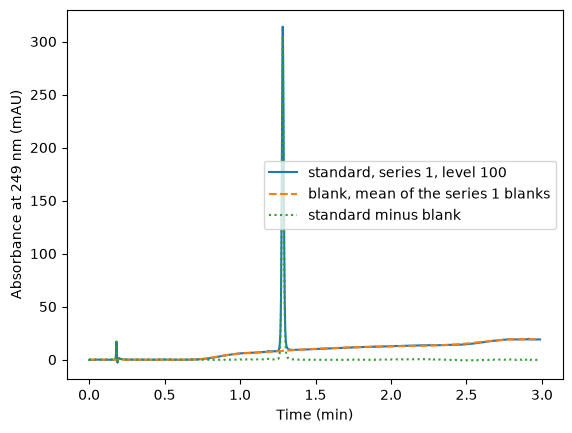

run: 2022-03-24_12-38-34_250_ba_100
apex at 1.283 min, 305.8 mAU after blank subtraction
blank at 249 nm: -0.2 to 19.7 mAU over the run


In [4]:
wavelength_column = str(WAVELENGTH_NM)


def blank_signal(series, time_min, column):
    """Average the blanks of one series and gradient, interpolated onto another run's time axis."""
    blank_runs = selected.loc[(selected["kind"] == "blank") & (selected["series"] == series), "run"]
    return np.mean([np.interp(time_min, runs[b]["time_min"], runs[b][column]) for b in blank_runs], axis=0)


is_example = (selected["kind"] == "standard") & (selected["series"] == 1) & (selected["level"] == "100")
example_name = selected.loc[is_example, "run"].iloc[0]
example_run = runs[example_name]
example_time = example_run["time_min"].to_numpy()  # min
example_raw = example_run[wavelength_column].to_numpy()  # mAU
example_blank = blank_signal(1, example_time, wavelength_column)  # mAU
example_corrected = example_raw - example_blank  # mAU

fig, ax = plt.subplots()
ax.plot(example_time, example_raw, linestyle="-", label=f"standard, series 1, level 100")
ax.plot(example_time, example_blank, linestyle="--", label="blank, mean of the series 1 blanks")
ax.plot(example_time, example_corrected, linestyle=":", label="standard minus blank")
ax.set_xlabel("Time (min)")
ax.set_ylabel(f"Absorbance at {WAVELENGTH_NM} nm (mAU)")
ax.legend()
plt.show()

apex_index = np.argmax(example_corrected)
print(f"run: {example_name}")
print(f"apex at {example_time[apex_index]:.3f} min, {example_corrected[apex_index]:.1f} mAU after blank subtraction")
print(f"blank at {WAVELENGTH_NM} nm: {example_blank.min():.1f} to {example_blank.max():.1f} mAU over the run")

The benzaldehyde peak is at 1.283 min and 305.8 mAU above the blank, which itself ranges from −0.2 to 19.7 mAU at 249 nm over the run.

## Choosing the detection wavelength

This figure shows the full spectrum at the peak apex, for the standard and for the blank at the same time, to choose the wavelength where benzaldehyde absorbs strongly and the blank is low. Expected output: one figure with the strongest absorbance near 200 nm and a second band near 249 nm, and the absorbance and blank at both.

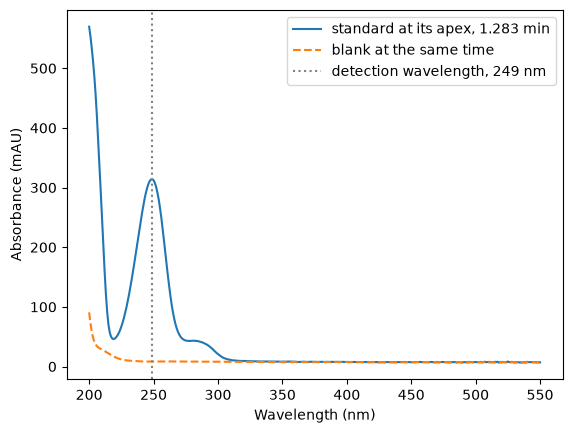

largest corrected absorbance: 480.9 mAU at 201 nm
largest above 240 nm: 305.8 mAU at 249 nm
blank at the apex: 72.7 mAU at 201 nm, 8.2 mAU at 249 nm


In [5]:
wavelength_columns = [c for c in example_run.columns if c != "time_min"]
wavelengths_nm = np.array(wavelength_columns, dtype=int)  # nm
apex_time = example_time[apex_index]  # min

standard_spectrum = example_run[wavelength_columns].iloc[apex_index].to_numpy()  # mAU
blank_spectrum = np.array([blank_signal(1, apex_time, c) for c in wavelength_columns])  # mAU

fig, ax = plt.subplots()
ax.plot(wavelengths_nm, standard_spectrum, linestyle="-", label=f"standard at its apex, {apex_time:.3f} min")
ax.plot(wavelengths_nm, blank_spectrum, linestyle="--", label="blank at the same time")
ax.axvline(WAVELENGTH_NM, color="gray", linestyle=":", label=f"detection wavelength, {WAVELENGTH_NM} nm")
ax.set_xlabel("Wavelength (nm)")
ax.set_ylabel("Absorbance (mAU)")
ax.legend()
plt.show()

corrected_spectrum = standard_spectrum - blank_spectrum  # mAU
above_240 = wavelengths_nm >= 240
best_above_240 = wavelengths_nm[above_240][np.argmax(corrected_spectrum[above_240])]
print(f"largest corrected absorbance: {corrected_spectrum.max():.1f} mAU at {wavelengths_nm[np.argmax(corrected_spectrum)]} nm")
print(f"largest above 240 nm: {corrected_spectrum[above_240].max():.1f} mAU at {best_above_240} nm")
print(f"blank at the apex: {blank_spectrum[wavelengths_nm == 201][0]:.1f} mAU at 201 nm, "
      f"{blank_spectrum[wavelengths_nm == WAVELENGTH_NM][0]:.1f} mAU at {WAVELENGTH_NM} nm")

The corrected absorbance is largest at 201 nm (480.9 mAU), but the blank there is 72.7 mAU against 8.2 mAU at 249 nm, the band maximum above 240 nm (305.8 mAU), so detection uses 249 nm; the position of this band should be checked against a literature UV spectrum of benzaldehyde.

## Peak areas of the benzaldehyde standards

For each of the 8 benzaldehyde standards on the 2.50 min gradient (4 levels × 2 series), this cell subtracts the blank of the same series at 249 nm, finds the apex, and integrates the peak with the trapezoid rule over the apex ± 0.05 min (± 3 s). The area is in mAU s. The scientific choice is the window: the peak is about 0.8 s wide at half height, so ± 3 s takes in the whole peak with little baseline. Expected output: a table of 8 standards whose area per mM should be about the same for all of them.

In [6]:
standards = selected[selected["kind"] == "standard"].copy()

areas = []
apex_times = []
heights = []
for _, standard in standards.iterrows():
    run = runs[standard["run"]]
    time_min = run["time_min"].to_numpy()  # min
    corrected = run[wavelength_column].to_numpy() - blank_signal(standard["series"], time_min, wavelength_column)  # mAU
    apex = time_min[np.argmax(corrected)]  # min
    in_window = (time_min >= apex - HALF_WINDOW_MIN) & (time_min <= apex + HALF_WINDOW_MIN)
    areas.append(np.trapezoid(corrected[in_window], time_min[in_window] * 60))  # mAU s
    apex_times.append(apex)
    heights.append(corrected.max())

standards["conc_mM"] = [CONCENTRATIONS_MM[ANALYTE][level] for level in standards["level"]]  # mM
standards["apex_min"] = apex_times  # min
standards["height_mAU"] = heights  # mAU
standards["area_mAU_s"] = areas  # mAU s
standards["area_per_mM"] = standards["area_mAU_s"] / standards["conc_mM"]  # mAU s per mM

print(standards[["series", "level", "conc_mM", "apex_min", "height_mAU", "area_mAU_s", "area_per_mM"]].round(3).to_string(index=False))

 series level  conc_mM  apex_min  height_mAU  area_mAU_s  area_per_mM
      1   025    0.249     1.287      76.055      74.217      298.542
      1   050    0.484     1.286     149.085     145.272      300.087
      1   075    0.762     1.284    2442.700    2635.351     3459.374
      1   100    0.995     1.283     305.780     294.289      295.857
      2   025    0.249     1.289      77.125      76.970      309.616
      2   050    0.484     1.288     148.810     145.085      299.700
      2   075    0.762     1.288     228.300     223.970      294.001
      2   100    0.995     1.287     303.800     297.794      299.380


Seven of the eight standards give 294 to 310 mAU s per mM, but series 1 level 075 gives 3459 mAU s per mM, about 12 times as much, with a peak height of 2443 mAU.

## First analysis: the calibration line

This cell fits a straight line of peak area against concentration with `scipy.stats.linregress`, which gives the slope and its standard error, first with all 8 standards and then without the standards in `EXCLUDED_STANDARDS`. A straight line is the method because, under the Beer–Lambert law, peak area is proportional to the amount injected, and there are 4 concentrations from 0.25 to 0.99 mM in each of 2 series. Expected output: both fits, printed with slope, intercept, R² and residual standard deviation, and a figure of the standards with the line fitted without the excluded point.

**The excluded standard.** Series 1, level 075 has 12 times the area per mM of the other seven standards, while level 075 of series 2 falls on the line with the others.

I would exclude the series 1 lvl 075 standard, because it is a large outlier (area per mM of 3459 vs ~300 for the other seven standards, with a peak height of 2443 mAU vs 228 mAU for series 2 lvl 075). Including it changes the slope drastically and does not fit the rest of the data well in comparison to excluding it (with, slope = 824.8 ± 1135.0 mAU s/mM and R² 0.08; without, slope = 294.6 ± 2.5 and R² 0.9996).

all standards (8 points): slope 824.8 ± 1135.0 mAU s/mM, intercept -26.6 ± 775.2 mAU s, R² 0.0809, residual SD 903.57 mAU s
without EXCLUDED_STANDARDS (7 points): slope 294.6 ± 2.5 mAU s/mM, intercept 2.2 ± 1.7 mAU s, R² 0.9996, residual SD 1.93 mAU s


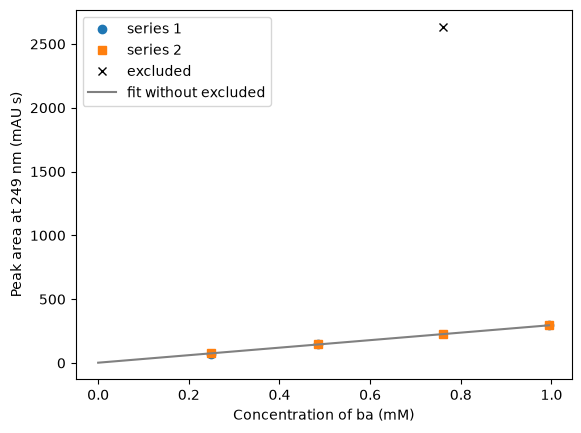

In [7]:
standards["excluded"] = [(s, l) in EXCLUDED_STANDARDS for s, l in zip(standards["series"], standards["level"])]
kept = standards[~standards["excluded"]]

fit_all = linregress(standards["conc_mM"], standards["area_mAU_s"])
fit_kept = linregress(kept["conc_mM"], kept["area_mAU_s"])

for name, fit, points in [("all standards", fit_all, standards), ("without EXCLUDED_STANDARDS", fit_kept, kept)]:
    residuals = points["area_mAU_s"] - (fit.intercept + fit.slope * points["conc_mM"])  # mAU s
    print(f"{name} ({len(points)} points): slope {fit.slope:.1f} ± {fit.stderr:.1f} mAU s/mM, "
          f"intercept {fit.intercept:.1f} ± {fit.intercept_stderr:.1f} mAU s, R² {fit.rvalue**2:.4f}, "
          f"residual SD {residuals.std(ddof=2):.2f} mAU s")

fig, ax = plt.subplots()
for series, marker in [(1, "o"), (2, "s")]:
    points = kept[kept["series"] == series]
    ax.plot(points["conc_mM"], points["area_mAU_s"], marker=marker, linestyle="none", label=f"series {series}")
ax.plot(standards.loc[standards["excluded"], "conc_mM"], standards.loc[standards["excluded"], "area_mAU_s"],
        marker="x", linestyle="none", color="black", label="excluded")
conc_line = np.linspace(0, standards["conc_mM"].max(), 50)  # mM
ax.plot(conc_line, fit_kept.intercept + fit_kept.slope * conc_line, linestyle="-", color="gray", label="fit without excluded")
ax.set_xlabel(f"Concentration of {ANALYTE} (mM)")
ax.set_ylabel(f"Peak area at {WAVELENGTH_NM} nm (mAU s)")
ax.legend()
plt.show()

Without the series 1 level 075 standard, the line has a slope of 294.6 ± 2.5 mAU s/mM and an intercept of 2.2 ± 1.7 mAU s (R² 0.9996, residual SD 1.93 mAU s); with it, the slope is 824.8 ± 1135.0 mAU s/mM and R² is 0.0809.

## Residuals of the calibration line

This figure shows the residuals of the fit without the excluded standard, to check the assumption of a straight line: they should scatter about zero with no curve, and with no offset between the two series. Expected output: 7 residuals of a few mAU s.

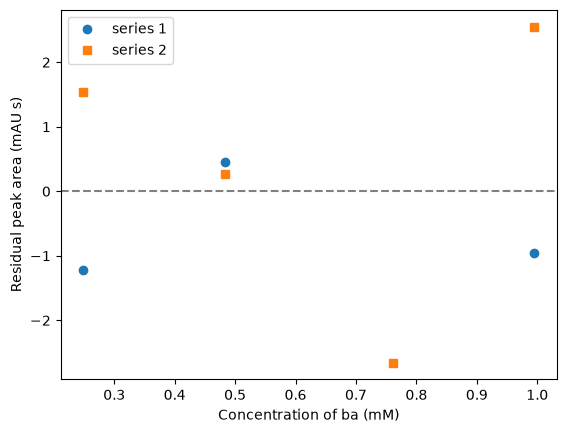

 series level  conc_mM  residual_mAU_s
      1   025     0.25           -1.21
      1   050     0.48            0.46
      1   100     0.99           -0.95
      2   025     0.25            1.54
      2   050     0.48            0.27
      2   075     0.76           -2.66
      2   100     0.99            2.55


In [8]:
kept_residuals = kept["area_mAU_s"] - (fit_kept.intercept + fit_kept.slope * kept["conc_mM"])  # mAU s

fig, ax = plt.subplots()
for series, marker in [(1, "o"), (2, "s")]:
    in_series = kept["series"] == series
    ax.plot(kept.loc[in_series, "conc_mM"], kept_residuals[in_series], marker=marker, linestyle="none", label=f"series {series}")
ax.axhline(0, color="gray", linestyle="--")
ax.set_xlabel(f"Concentration of {ANALYTE} (mM)")
ax.set_ylabel("Residual peak area (mAU s)")
ax.legend()
plt.show()

print(kept.assign(residual_mAU_s=kept_residuals)[["series", "level", "conc_mM", "residual_mAU_s"]].round(2).to_string(index=False))

The residuals lie between −2.66 and +2.55 mAU s, under 1% of the largest area, with no clear curve; the intercept of 2.2 ± 1.7 mAU s is within 1.3 standard errors of zero.

### Task 004. First-calibration analysis

Ran a calibration for one analyte (benzealdehyde) on one gradient (2.50 min). Detection wavelength chosen where benzaldehyde absorbs strongly and blank is also low: 305.8 mAU at 249 nm, blank at 8.2 mAU. Strongest corrected absorbance of 480.9 mAU at 201 nm not chosen due to high blank at 72.7 mAU. Cells 10–12 show the benzaldehyde peak at 1.283 min, 305.8 mAU above the blank. The blank drifts from −0.2 to 19.7 mAU at 249 nm over the run, subtracted from standard at each time point. Series 1 level 075 standard excluded as large outlier with area per mM of 3459 vs ~300 for the other seven standards, and a peak height of 2443 mAU vs 228 mAU for series 2 lvl 075. Excluding standard makes slope well fit to calibration results: with, slope = 824.8 ± 1135.0 mAU s/mM and R² 0.08; without, slope = 294.6 ± 2.5 and R² 0.9996. Residuals of calibration line demonstrate random scatter near zero with no curve or offset, indicating a straight line fit with left over as random noise: residuals lie between −2.66 and +2.55 mAU s, under 1% of the largest area, no clear curve; the intercept of 2.2 ± 1.7 mAU s is within 1.3 standard errors of zero. 

What exploration changed in plans:
Plan. Take absorbance, measure peak area for each standard, fit straight line, and get slope.
Changes. 
- Blank isnt flat, (drifts from −0.2 to 19.7 mAU at 249 nm over the run) so added step to subtract blank from standard at each time point.
- Despite the strongest band being at 201 nm, picked 249 nm because blank was closer to zero (72.7 mAU vs .2 mAU).
- Standard run for series 1 level 075 benzaldehyde is an outlier that sits much higher than the rest of data (3259 vs ~300), and gives bad slope when included (824.8, R^2 0.08), so is left excluded and task 006 is added to find out if the issue is the single injection or solution based across all gradients.

Reasons for using linear regression, slope, and Beer-Lambert:
- Beer-Lambert. More benzaldehyde gives more absorbance, and peak area sums absorbance over entire peak, so area is proportional to concentration. Area is used instead of height because area stays the same through longer gradient lengths and therefore widening of the peak.
- Linear regression. Beer-Lambert predicts a straight line, so best fit line is found and checked for fit.
- Slope. Shows sensitivity and area per 1 mM of benzealdehyde. Project compares the slope across the 5 gradients to see whether it changes by more than random noise.

## Next steps

Run calibrations for all analytes at all gradients and verify Beer-Lambert rule that area is proportional to concentration. Check series 1 level 075 standards for four other gradients and identify issue with solution or just the injection for first-calibration benzaldehyde series 1 level 075. For now, analysis assumes series 1 level 075 is the single outlier resulting from an injection issue or human error and is excluded. If it is a real result, there is a larger issue and will be checked by seeing if it's also high on other gradients (task 006).

Analysis currently assumes that a +-0.05 min window will cover whole peaks, however that area is too small for gradients with wider peaks. This will be checked by measuring the peak width on each gradient (task 007).

The concentrations from MOCCA's code are assumed, and if incorrect then slope would be off but data would not show issue. This will be compared with the Haas et al. paper.

Analysis assumes the blank has no peak of its own at 1.28 min, if there is one then subtracting the blank also removes part of the signal being analyzed. This can be checked by manually going through files and looking for steady values with no rise or fall (in _grad files), but will likely by inputted as a new cell in the notebook that plots all four blanks for the 2.50 min gradient (2 per series), zoomed in at ~1.00-1.50 at 249 nm, with a line at the benzaldehyde apex peak and edges of integration window marked for comparison. Results are expected to be flat, but if there is a bump then that would mean something in the solvent elutes with benzaldehyde.

Beer-Lambert says peak area depends on concentration of injected analyte and not gradient length (different from path length), so slope is expected to stay the same overall. Changes in slope could be due to different solvent mix peaks per gradient, and issues with coding/analysis (for example: +-0.05 min window cutoff). Testing where scatter comes from, injections or solutions. If noise shows more than random scatter, then analyze for patterns (one series always higher = differing solutions, drift over time = instrument changes, curve = response is not linear, scatter growth with concentration = error is percentage of signal, or carryover).

Thus far, Beer-Lambert law is consistent for first-calibration. Series 1 level 075 standard shows outlier (3459 vs ~300 mAU per mM), will check if also high on other gradients in later calibrations.

What the data cannot answer: 
- There are only 2 series, which is a small number to estimate noise.
- The concentrations are not recorded in the data files and were assumed from MOCCA's code, from level in each run name (ex: 075, meaning 75%). So if one is wrong, the whole slope is wrong because the concentration is the x-axis for plots, and the data will not show this.
- The data can show if solution/injection is the issue but not what happened, such as human errors.
- Small # of measurements can show a pattern in this dataset that may not apply for all HPLC or anything outside measured ranges.
- If slope does change and there is a chemical cause shown by data, the data cannot prove what exactly happened and why.

## Versions

Expected output: the versions of Python and the packages this notebook ran with.

In [9]:
print(f"Python     {sys.version.split()[0]}")
print(f"NumPy      {np.__version__}")
print(f"pandas     {pd.__version__}")
print(f"SciPy      {scipy.__version__}")
print(f"Matplotlib {matplotlib.__version__}")

Python     3.14.10
NumPy      2.5.3
pandas     3.0.6
SciPy      1.18.1
Matplotlib 3.11.2
